# B04-KM — Thuận

Phân công khớp chính xác mốc `2026-11-17T21:00:00.000Z` trong workbook nguồn.
Ngày giờ Việt Nam: **04:00 ngày 18/11/2026**. Mã thư mục giữ ngày của mốc UTC.

Cấu hình: `B04`, `KMeans`. Nguồn duy nhất:
`data/raw/Online Retail.xlsx`, SHA-256 `43465a06f2ccf7c8b5bd2892bc7defb52f97487934fe93b16ae4c3936424676d`.

Notebook mặc định đọc kết quả đã chạy. Đổi `RUN_AGAIN = True` để dựng lại từ raw,
quét tham số và ghi lại **chỉ thư mục kết quả của thí nghiệm này**.
Mọi nhãn cụm gắn với CustomerID; Monetary là giá trị mua lịch sử GBP.


In [1]:
from pathlib import Path
import sys, json
import numpy as np
import pandas as pd
from IPython.display import display, Image, Markdown
from threadpoolctl import threadpool_limits

REL = Path("project/experiments/thuan_deadline_2026_11_17")
candidates = [q for p in [Path.cwd(), *Path.cwd().parents] for q in [p, p / REL]]
BASE = next(q for q in candidates if (q / "run_experiments.py").is_file())
if str(BASE) not in sys.path: sys.path.insert(0, str(BASE))
import run_experiments as runner


In [2]:
EXPERIMENT = "B04-KM"
RUN_AGAIN = False
if RUN_AGAIN:
    with threadpool_limits(limits=1):
        rfm, cleaning, provenance = runner.prepare_input()
        runner.run_one(EXPERIMENT, rfm)
        runner.workbook(runner.assignments(), rfm, cleaning, provenance)
OUT = BASE / "results" / EXPERIMENT
params = json.loads((OUT / "parameters.json").read_text(encoding="utf-8"))
assert params["status"] == "completed"
display(pd.Series({
    "Thí nghiệm": EXPERIMENT,
    "Mô hình": params["actual_model"],
    "Khách": params["customers"],
    "Số chiều đầu vào": params["preprocessing"]["model_input_dimensions"],
    "Biến đổi": params["preprocessing"]["transform"],
    "Scaler": params["preprocessing"]["scaler"],
    "PCA": params["preprocessing"]["pca_requested"],
}).to_frame("Giá trị"))
print(json.dumps(params["preprocessing"], ensure_ascii=False, indent=2))


,Giá trị
Thí nghiệm,B04-KM
Mô hình,KMeans
Khách,4327
Số chiều đầu vào,2
Biến đổi,log_all
Scaler,MinMaxScaler
PCA,0.9


{
  "configuration": "B04",
  "transform": "log_all",
  "scaler": "MinMaxScaler",
  "pca_requested": 0.9,
  "model_input_dimensions": 2,
  "pca_explained_variance_ratio": [
    0.790102363889695,
    0.17964678452928523
  ],
  "pca_explained_variance_total": 0.9697491484189802,
  "pca_components": [
    [
      0.8736496461356037,
      -0.40243547643542277,
      -0.273462946508898
    ],
    [
      0.48566302989491716,
      0.6872528575683081,
      0.5401989736731121
    ]
  ]
}


## Quét tham số và lựa chọn
GN dùng GNN Graph Autoencoder hai lớp GCN rồi K-Means trên embedding học được. Silhouette GN tính trên embedding; KM tính trên PCA/scaler input; DBSCAN tính trên khách không nhiễu. Các không gian này không so trực tiếp. Checkpoint GNN chọn theo BCE validation, không theo test.

,Được chọn
k,2
n_clusters,2
noise_pct,0.0
smallest_cluster,1873
largest_cluster_pct_all,56.713658
silhouette,0.466793
dbi,0.808393
chi,5413.424998
warnings,
inertia,179.79191


,k,n_clusters,noise_pct,smallest_cluster,largest_cluster_pct_all,silhouette,dbi,chi,warnings,inertia,eligible
0,2,2,0.0,1873,56.713658,0.466793,0.808393,5413.424998,NaN,179.791910,True
1,3,3,0.0,1020,41.922810,0.395902,0.904186,4971.157901,NaN,122.704355,True
2,4,4,0.0,793,33.787844,0.398373,0.915073,4555.475550,NaN,97.283958,True
3,5,5,0.0,457,29.697250,0.394939,0.875558,4695.266474,NaN,75.734169,True
4,6,6,0.0,356,25.745320,0.396797,0.840205,4724.005797,NaN,62.607808,True
5,7,7,0.0,245,24.890224,0.389727,0.793192,4747.983109,NaN,53.306816,True
6,8,8,0.0,195,20.406748,0.381359,0.808038,4686.990988,NaN,47.094072,True
7,9,9,0.0,179,19.020106,0.378577,0.819900,4643.097624,NaN,42.160539,True
8,10,10,0.0,146,18.973885,0.372617,0.829868,4645.620175,NaN,37.887542,True


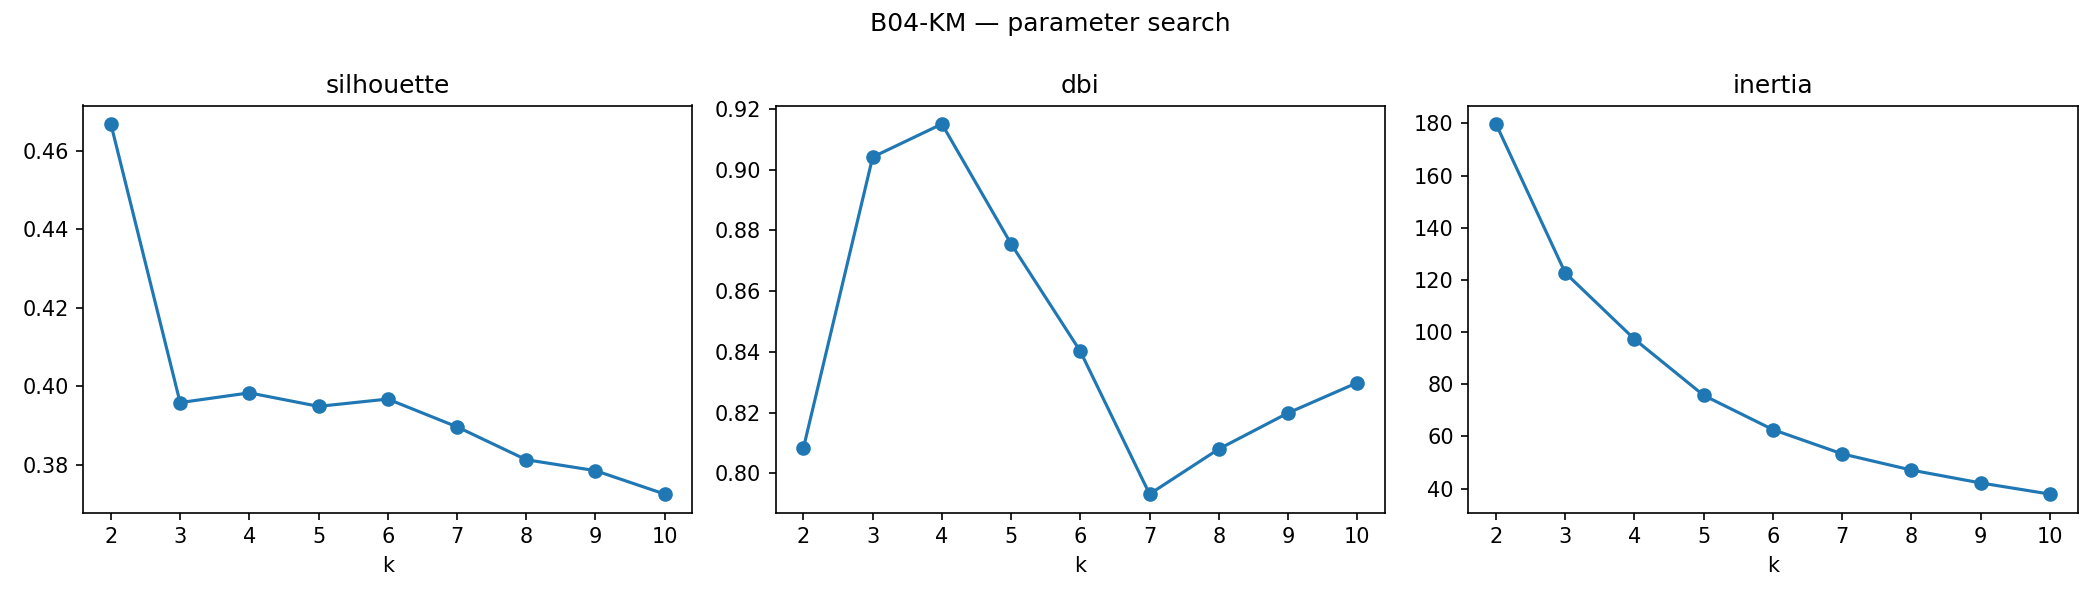

In [3]:
grid = pd.read_csv(OUT / "search.csv")
display(pd.Series(params["selected"]).to_frame("Được chọn"))
display(grid)
display(Image(filename=str(OUT / "figures" / "search.png")))
if "gnn_training" in params:
    print(json.dumps(params["gnn_training"], ensure_ascii=False, indent=2))
    display(Image(filename=str(OUT / "figures" / "training.png")))
    display(pd.read_csv(OUT / "training_history.csv"))


## Nhãn và hồ sơ cụm
Hình chỉ hiển thị hai tọa độ đầu; bảng RFM dùng đơn vị gốc.

,CustomerID,Recency,Frequency,Monetary,cluster
0,12347,3,7,4310.00,1
1,12348,76,4,1437.24,0
2,12349,19,1,1457.55,1
3,12350,311,1,294.40,0
4,12352,37,7,1385.74,1
5,12353,205,1,89.00,0
6,12354,233,1,1079.40,0
7,12355,215,1,459.40,0
8,12356,23,3,2487.43,1
9,12357,34,1,6207.67,1


,cluster,customers,Recency_median,Frequency_median,Monetary_median,Monetary_sum,customer_pct,monetary_pct
0,0,2454,120.0,1.0,383.80,1632872.902,56.713658,19.402495
1,1,1873,16.0,5.0,1488.67,6782915.471,43.286342,80.597505


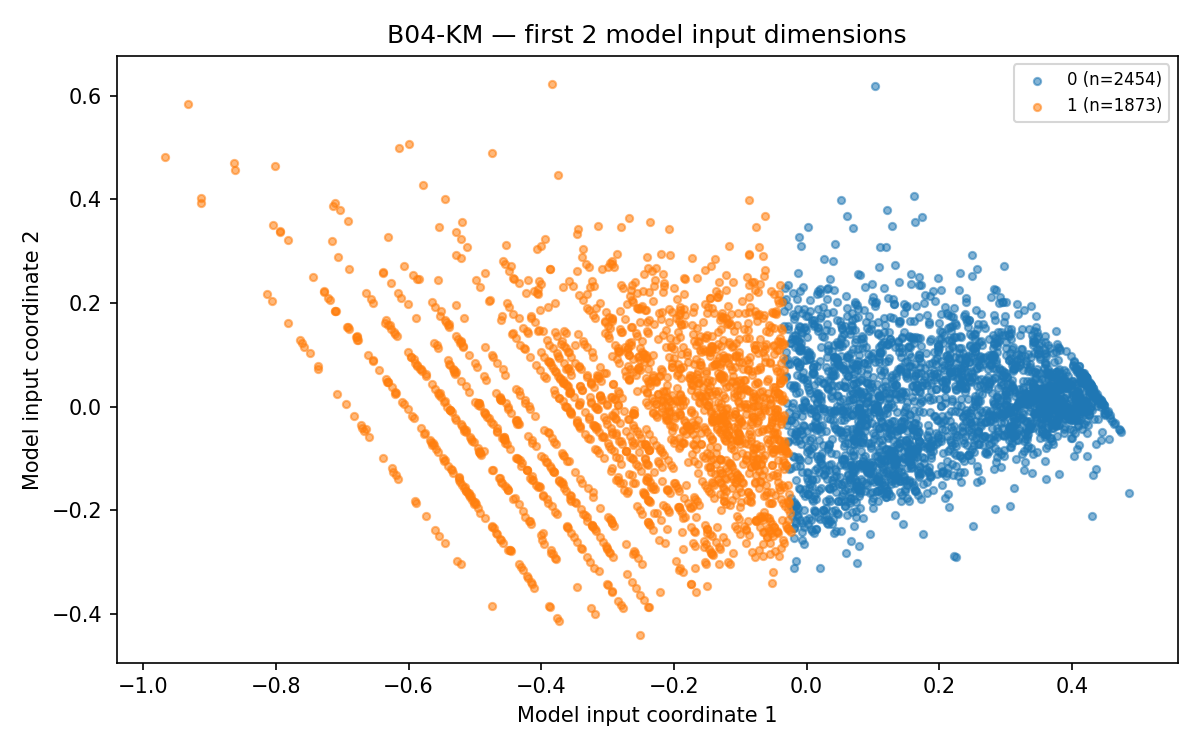

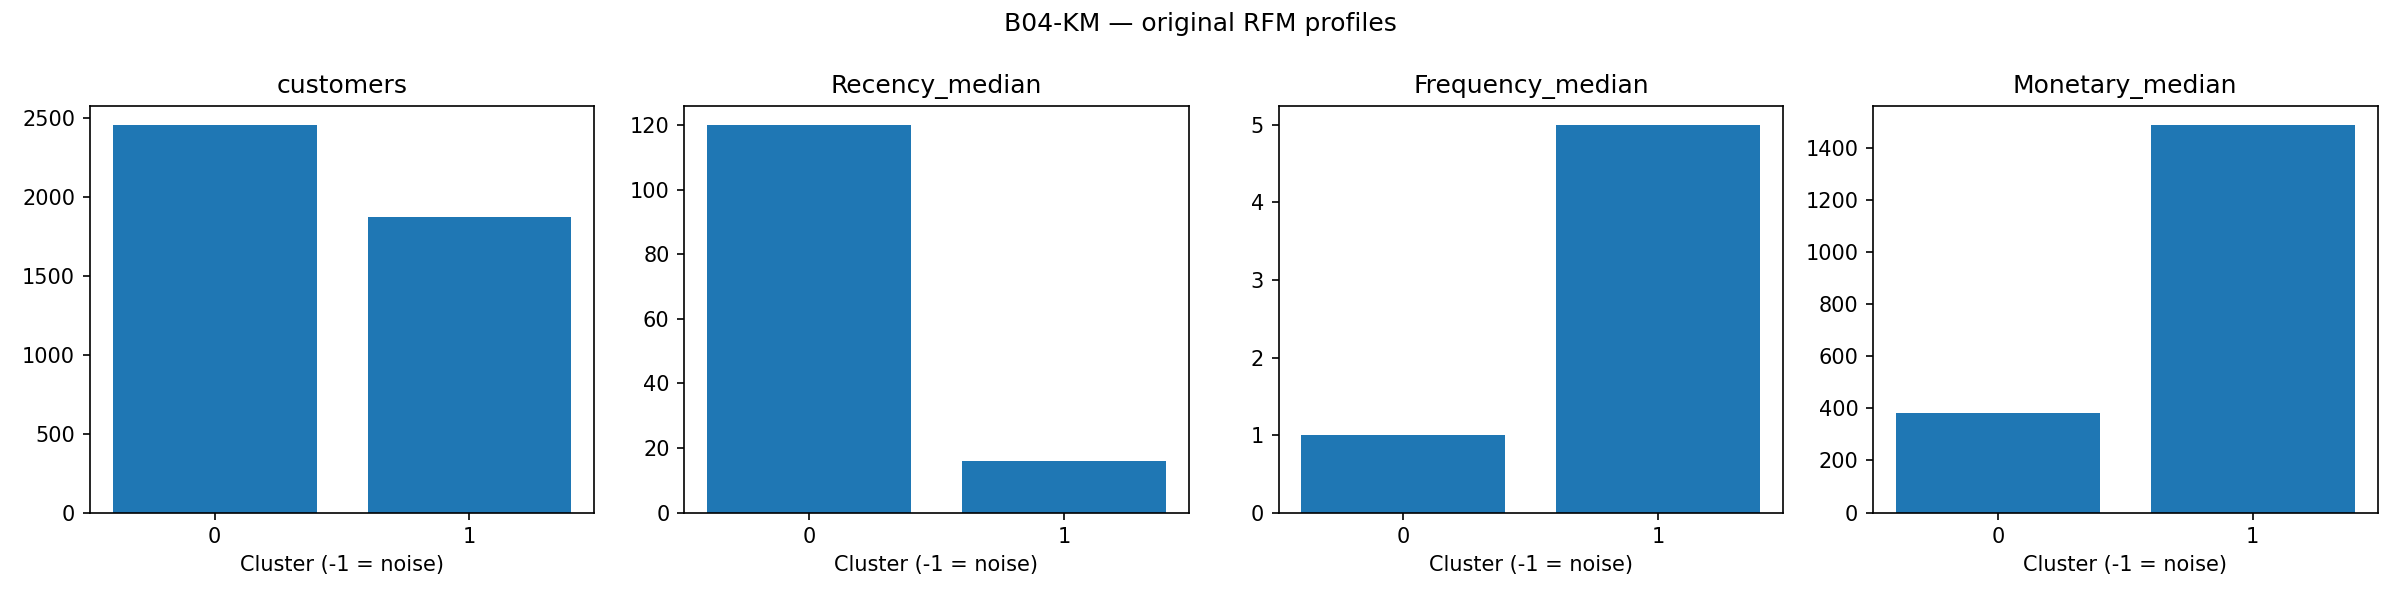

In [4]:
labels = pd.read_csv(OUT / "labels.csv", dtype={"CustomerID": str})
profiles = pd.read_csv(OUT / "profiles.csv")
assert labels.CustomerID.is_unique and len(labels) == params["customers"]
display(labels.head(10))
display(profiles)
display(Image(filename=str(OUT / "figures" / "clusters.png")))
display(Image(filename=str(OUT / "figures" / "profiles.png")))
if (OUT / "figures" / "k_distance.png").exists():
    display(Image(filename=str(OUT / "figures" / "k_distance.png")))


## Đối chiếu và giới hạn
Parent diagnostic giữ tham số đã chọn ở target, không phải baseline được tune độc lập. GNN dùng đồ thị kNN từ RFM, nên AUC/AP liên kết chỉ đánh giá tái dựng graph; không có BIC/AIC. GNN có tính transductive: suy luận chỉ áp dụng tập khách gốc đúng thứ tự.

In [5]:
if params.get("comparison"):
    print(json.dumps(params["comparison"], ensure_ascii=False, indent=2))
print("Chỉ số trên StandardScaler(RFM gốc), dùng cùng không gian tham chiếu:")
display(pd.Series(params["all_customers_common_space_scores"]).to_frame("Giá trị"))
display(Markdown("\n".join("- " + note for note in params["limitations"])))


{
  "parent_configuration": "B01",
  "purpose": "fixed-parameter preprocessing diagnostic, not a tuned parent experiment",
  "target_dimensions": 2,
  "parent_dimensions": 2,
  "ari": 0.5156821117967471,
  "target_common_rfm_scores": {
    "n_clusters": 2,
    "noise_pct": 0.0,
    "smallest_cluster": 1873,
    "largest_cluster_pct_all": 56.71365842385024,
    "silhouette": 0.31897836991328704,
    "dbi": 1.1520347509944373,
    "chi": 1042.3843675896262
  },
  "parent_common_rfm_scores": {
    "n_clusters": 2,
    "noise_pct": 0.0,
    "smallest_cluster": 1660,
    "largest_cluster_pct_all": 61.636237577998614,
    "silhouette": 0.27465798425214927,
    "dbi": 1.2788561110743357,
    "chi": 888.6767173509069
  },
  "parent_input_scores": {
    "n_clusters": 2,
    "noise_pct": 0.0,
    "smallest_cluster": 1660,
    "largest_cluster_pct_all": 61.636237577998614,
    "silhouette": 0.46389778376046925,
    "dbi": 0.8202790185535682,
    "chi": 4985.948976631496
  },
  "parent_preprocessi

,Giá trị
n_clusters,2.000000
noise_pct,0.000000
smallest_cluster,1873.000000
largest_cluster_pct_all,56.713658
silhouette,0.318978
dbi,1.152035
chi,1042.384368


- Exploratory clustering, not future value prediction; Monetary is historical sales, not profit.
- No ground-truth labels or held-out predictive evaluation.
- Internal scores from different feature spaces and DBSCAN subsets are not directly comparable.
- The cleaning policy reproduces the shared group RFM; it is not a newly approved official policy.

## Kiểm tra mô hình đã lưu

In [6]:
import joblib
pipeline = joblib.load(OUT / "pipeline.joblib")
X = labels[runner.FEATURES]
Z = pipeline["preprocessing"].transform(X)
saved = pd.read_csv(OUT / "model_input.csv").filter(like="input_").to_numpy()
np.testing.assert_allclose(Z, saved, atol=1e-9, rtol=0)
if params["actual_model"] != "DBSCAN":
    np.testing.assert_array_equal(pipeline.predict(X), labels.cluster)
else:
    np.testing.assert_array_equal(pipeline["model"].labels_, labels.cluster)
    print("DBSCAN không có predict cho khách mới; labels_ gắn với đúng thứ tự khách khi fit.")
print("PASS — mô hình lưu, dữ liệu đầu vào và nhãn khớp nhau.")


PASS — mô hình lưu, dữ liệu đầu vào và nhãn khớp nhau.
